# AI-Based Predictive Decision Support System
**SparkIIT AI Project 2** | Machine Learning, Predictive Analytics, Classification, Data Analysis

**Objective:** Estimate the probability that a borrower will experience serious financial distress (90 or more days past due) within two years, compare several machine learning models, turn the probability into a cost-aware approve / review / decline recommendation, and wrap the best model in an interactive prediction interface. The system supports a human decision maker. It does not replace one.

**Dataset:** Kaggle competition *Give Me Some Credit* (https://www.kaggle.com/c/GiveMeSomeCredit), file `cs-training.csv`, 150,000 real borrowers. Download it from the competition's Data tab (you must be logged in and accept the rules) and upload it when the notebook asks.

In [1]:
import os
import zipfile
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.base import clone
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, roc_curve,
                             precision_recall_curve, precision_score, recall_score, f1_score)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
RANDOM_STATE = 42
TARGET = "SeriousDlqin2yrs"
print("Libraries loaded")

Libraries loaded


## 1. Load the dataset
Run this cell and use the file picker to upload `cs-training.csv` (or the `GiveMeSomeCredit.zip` you downloaded from Kaggle).

In [2]:
if not os.path.exists("cs-training.csv"):
    try:
        from google.colab import files
        print("Choose cs-training.csv (or the Kaggle zip) in the file picker...")
        uploaded = files.upload()
    except ImportError:
        raise FileNotFoundError("Put cs-training.csv in the same folder as this notebook.")
    for name in uploaded:
        if name.lower().endswith(".zip"):
            with zipfile.ZipFile(name) as z:
                member = [m for m in z.namelist() if m.lower().endswith("cs-training.csv")][0]
                z.extract(member, ".")
                os.replace(member, "cs-training.csv")
        elif name != "cs-training.csv":
            os.replace(name, "cs-training.csv")
raw = pd.read_csv("cs-training.csv")
print("Loaded:", raw.shape)

Choose cs-training.csv (or the Kaggle zip) in the file picker...


Saving GiveMeSomeCredit.zip to GiveMeSomeCredit.zip
Loaded: (150000, 12)


## 2. Check data quality
Real data is messy. Before modelling, look for impossible values and special codes.

In [3]:
df = raw.loc[:, ~raw.columns.str.startswith("Unnamed")].copy()
print("Rows, columns:", df.shape)
print(f"Serious delinquency rate: {df[TARGET].mean():.4f}  ({int(df[TARGET].sum())} of {len(df)} borrowers)")
print("\nMissing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nData problems found:")
print("  age below 18:", int((df["age"] < 18).sum()))
for c in ["NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfTimes90DaysLate"]:
    print(f"  {c} >= 90 (special codes):", int((df[c] >= 90).sum()))
print("  utilization above 2 (over 200% of limits):", int((df["RevolvingUtilizationOfUnsecuredLines"] > 2).sum()))
before = len(df)
df = df[df["age"] >= 18].reset_index(drop=True)
print(f"\nDropped {before - len(df)} row(s) with impossible age. Rows left: {len(df)}")
df.describe().T.round(2)

Rows, columns: (150000, 11)
Serious delinquency rate: 0.0668  (10026 of 150000 borrowers)

Missing values per column:
MonthlyIncome         29731
NumberOfDependents     3924
dtype: int64

Data problems found:
  age below 18: 1
  NumberOfTime30-59DaysPastDueNotWorse >= 90 (special codes): 269
  NumberOfTime60-89DaysPastDueNotWorse >= 90 (special codes): 269
  NumberOfTimes90DaysLate >= 90 (special codes): 269
  utilization above 2 (over 200% of limits): 371

Dropped 1 row(s) with impossible age. Rows left: 149999


,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,149999.0,0.07,0.25,0.0,0.00,0.00,0.00,1.0
RevolvingUtilizationOfUnsecuredLines,149999.0,6.05,249.76,0.0,0.03,0.15,0.56,50708.0
age,149999.0,52.30,14.77,21.0,41.00,52.00,63.00,109.0
NumberOfTime30-59DaysPastDueNotWorse,149999.0,0.42,4.19,0.0,0.00,0.00,0.00,98.0
DebtRatio,149999.0,353.01,2037.83,0.0,0.18,0.37,0.87,329664.0
MonthlyIncome,120268.0,6670.23,14384.73,0.0,3400.00,5400.00,8249.00,3008750.0
NumberOfOpenCreditLinesAndLoans,149999.0,8.45,5.15,0.0,5.00,8.00,11.00,58.0
NumberOfTimes90DaysLate,149999.0,0.27,4.17,0.0,0.00,0.00,0.00,98.0
NumberRealEstateLoansOrLines,149999.0,1.02,1.13,0.0,0.00,1.00,2.00,54.0
NumberOfTime60-89DaysPastDueNotWorse,149999.0,0.24,4.16,0.0,0.00,0.00,0.00,98.0


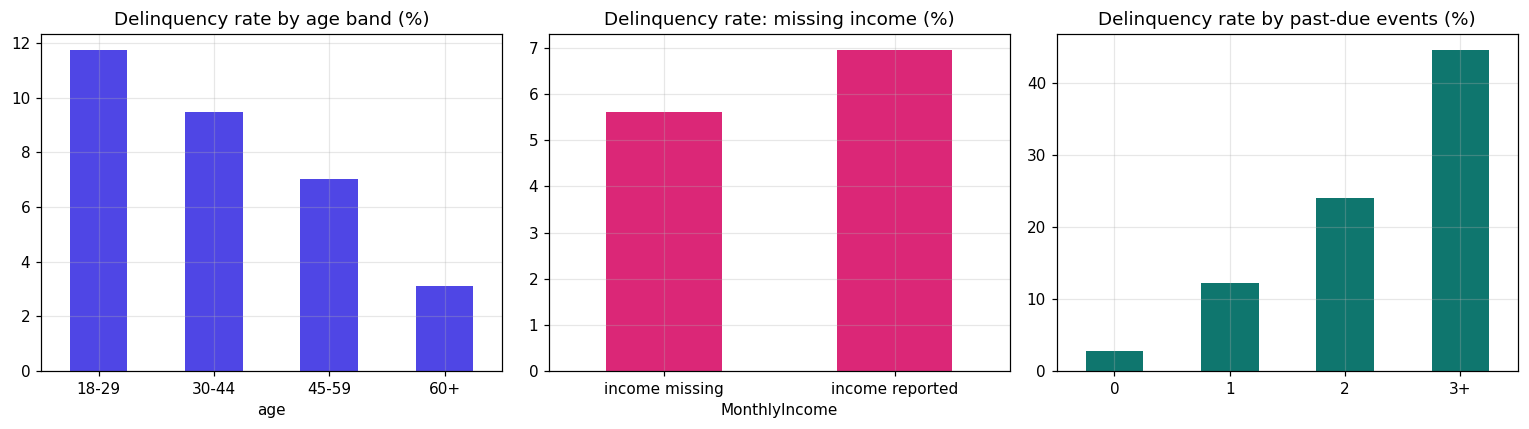

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
bands = pd.cut(df["age"], [17, 29, 44, 59, 120], labels=["18-29", "30-44", "45-59", "60+"])
df.groupby(bands)[TARGET].mean().mul(100).plot(kind="bar", ax=ax[0], color="#4F46E5", rot=0)
ax[0].set_title("Delinquency rate by age band (%)")
df.groupby(df["MonthlyIncome"].isna().map({True: "income missing", False: "income reported"}))[TARGET].mean().mul(100).plot(kind="bar", ax=ax[1], color="#DB2777", rot=0)
ax[1].set_title("Delinquency rate: missing income (%)")
pdue = df[["NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfTimes90DaysLate"]].where(lambda x: x < 90).sum(axis=1)
df.groupby(pd.cut(pdue, [-1, 0, 1, 2, 100], labels=["0", "1", "2", "3+"]))[TARGET].mean().mul(100).plot(kind="bar", ax=ax[2], color="#0F766E", rot=0)
ax[2].set_title("Delinquency rate by past-due events (%)")
plt.tight_layout()
plt.savefig("fig_eda.png", dpi=150)
plt.show()

## 3. Split first, then engineer features
The data is split before any statistics are calculated, so the test set stays untouched. Caps for extreme values are computed from the training part only. Features added: total past-due events, an ever-late flag, log income, log debt ratio and income per dependent.

In [5]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE, stratify=df[TARGET])
y_train, y_test = train_df[TARGET], test_df[TARGET]
X_train_raw, X_test_raw = train_df.drop(columns=TARGET), test_df.drop(columns=TARGET)
caps = {"util": float(X_train_raw["RevolvingUtilizationOfUnsecuredLines"].quantile(0.99)),
        "debt": float(X_train_raw["DebtRatio"].quantile(0.99)),
        "income": float(X_train_raw["MonthlyIncome"].quantile(0.995))}
print("Caps from training data:", {k: round(v, 2) for k, v in caps.items()})

PAST_DUE = ["NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfTimes90DaysLate"]


def add_features(d, caps):
    d = d.copy()
    for c in PAST_DUE:
        d[c] = d[c].where(d[c] < 90)   # codes 96 and 98 are data errors, treated as missing
    d["RevolvingUtilizationOfUnsecuredLines"] = d["RevolvingUtilizationOfUnsecuredLines"].clip(upper=caps["util"])
    d["DebtRatio"] = d["DebtRatio"].clip(upper=caps["debt"])
    d["MonthlyIncome"] = d["MonthlyIncome"].clip(upper=caps["income"])
    d["total_past_due"] = d[PAST_DUE].sum(axis=1, min_count=1)
    d["ever_late"] = (d["total_past_due"].fillna(0) > 0).astype(int)
    d["log_monthly_income"] = np.log1p(d["MonthlyIncome"])
    d["log_debt_ratio"] = np.log1p(d["DebtRatio"])
    d["income_per_dependent"] = d["MonthlyIncome"] / (d["NumberOfDependents"] + 1)
    return d


X_train = add_features(X_train_raw, caps)
X_test = add_features(X_test_raw, caps)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Delinquency rate  train: %.4f  test: %.4f" % (y_train.mean(), y_test.mean()))
print("Engineered:", [c for c in X_train.columns if c not in X_train_raw.columns])

Caps from training data: {'util': 1.1, 'debt': 4983.04, 'income': 35000.0}
Train: (119999, 15) | Test: (30000, 15)
Delinquency rate  train: 0.0668  test: 0.0668
Engineered: ['total_past_due', 'ever_late', 'log_monthly_income', 'log_debt_ratio', 'income_per_dependent']


## 4. Pipeline and candidate models
Imputing (with missing-value flags), scaling, feature selection (ANOVA F-test) and the model all sit in one pipeline, so cross-validation never leaks information from validation folds. No class weighting is used, so the predicted probabilities stay honest.

In [6]:
def build(model, k="all"):
    return Pipeline([
        ("imp", SimpleImputer(strategy="median", add_indicator=True)),
        ("sc", StandardScaler()),
        ("select", SelectKBest(f_classif, k=k)),
        ("model", model),
    ])


models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=10, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(max_iter=300, random_state=RANDOM_STATE),
}
print("Models:", list(models))

Models: ['Logistic Regression', 'Random Forest', 'Hist Gradient Boosting']


## 5. Compare models with 5-fold cross-validation
Only about 6 to 7 percent of borrowers become seriously delinquent, so plain accuracy is misleading: a model that approves everyone is about 93 percent accurate and useless. ROC-AUC and PR-AUC (higher is better) and the Brier score (lower is better) are used instead.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"ROC-AUC": "roc_auc", "PR-AUC": "average_precision", "Brier": "neg_brier_score"}
rows = []
for name, m in models.items():
    res = cross_validate(build(m), X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    row = {"Model": name}
    for label in scoring:
        vals = res["test_" + label] * (-1 if label == "Brier" else 1)
        row[label] = f"{vals.mean():.4f} +/- {vals.std():.4f}"
        row[label + "_mean"] = vals.mean()
    rows.append(row)
cv_df = pd.DataFrame(rows).set_index("Model")
cv_df[list(scoring)]

,ROC-AUC,PR-AUC,Brier
Model,,,
Logistic Regression,0.8560 +/- 0.0069,0.3848 +/- 0.0092,0.0500 +/- 0.0004
Random Forest,0.8631 +/- 0.0061,0.3992 +/- 0.0083,0.0492 +/- 0.0004
Hist Gradient Boosting,0.8622 +/- 0.0056,0.3974 +/- 0.0079,0.0492 +/- 0.0004


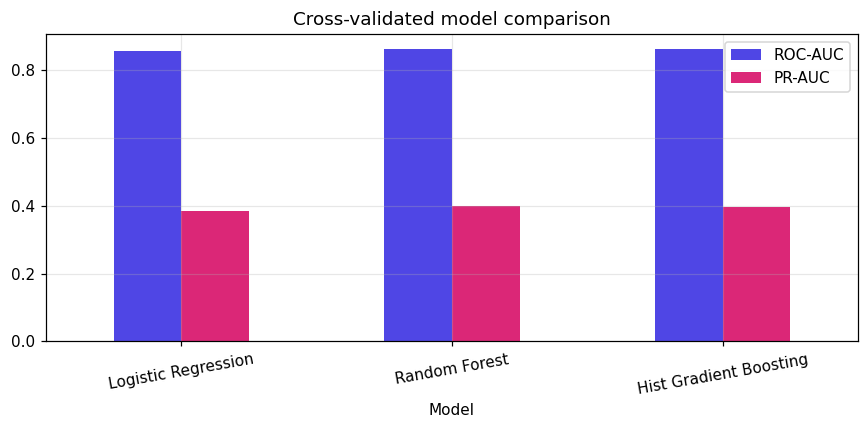

In [8]:
ax = cv_df[["ROC-AUC_mean", "PR-AUC_mean"]].rename(columns={"ROC-AUC_mean": "ROC-AUC", "PR-AUC_mean": "PR-AUC"}).plot(
    kind="bar", figsize=(8, 4), rot=10, color=["#4F46E5", "#DB2777"])
ax.set_title("Cross-validated model comparison")
plt.tight_layout()
plt.savefig("fig_cv_comparison.png", dpi=150)
plt.show()

## 6. Tune the best model
The model with the best cross-validated ROC-AUC is tuned with GridSearchCV (3 folds). The grid also tunes how many features to keep, which is the feature selection step.

In [9]:
grids = {
    "Logistic Regression": {"select__k": [8, "all"], "model__C": [0.1, 1, 10]},
    "Random Forest": {"select__k": [8, "all"], "model__max_depth": [8, 12], "model__min_samples_leaf": [20, 50]},
    "Hist Gradient Boosting": {"select__k": [8, "all"], "model__learning_rate": [0.05, 0.1],
                               "model__max_leaf_nodes": [15, 31], "model__l2_regularization": [0.0, 1.0]},
}
best_name = cv_df["ROC-AUC_mean"].idxmax()
base_auc = cv_df.loc[best_name, "ROC-AUC_mean"]
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(build(models[best_name]), grids[best_name], cv=cv3, scoring="roc_auc", n_jobs=1)
grid.fit(X_train, y_train)
best_pipe = grid.best_estimator_
print("Selected model:", best_name)
print("Best params:", grid.best_params_)
print(f"CV ROC-AUC before tuning (5-fold): {base_auc:.4f} | tuned (3-fold): {grid.best_score_:.4f}")
print("(the two numbers use different folds, so a tiny difference means tuning changed little)")
try:
    kept = best_pipe[:-1].get_feature_names_out()
    print(len(kept), "features kept after selection")
except Exception as e:
    print("Could not list kept features:", e)

Selected model: Random Forest
Best params: {'model__max_depth': 12, 'model__min_samples_leaf': 20, 'select__k': 'all'}
CV ROC-AUC before tuning (5-fold): 0.8631 | tuned (3-fold): 0.8639
(the two numbers use different folds, so a tiny difference means tuning changed little)
23 features kept after selection


## 7. Final check on the held-out test set

Test rows: 30000 | delinquency rate: 0.0668
ROC-AUC : 0.8681
PR-AUC  : 0.3956
Brier   : 0.0490
PR-AUC of a model with no skill equals the base rate: 0.0668
Accuracy of 'approve everyone': 0.9332 (this is why accuracy is not used)


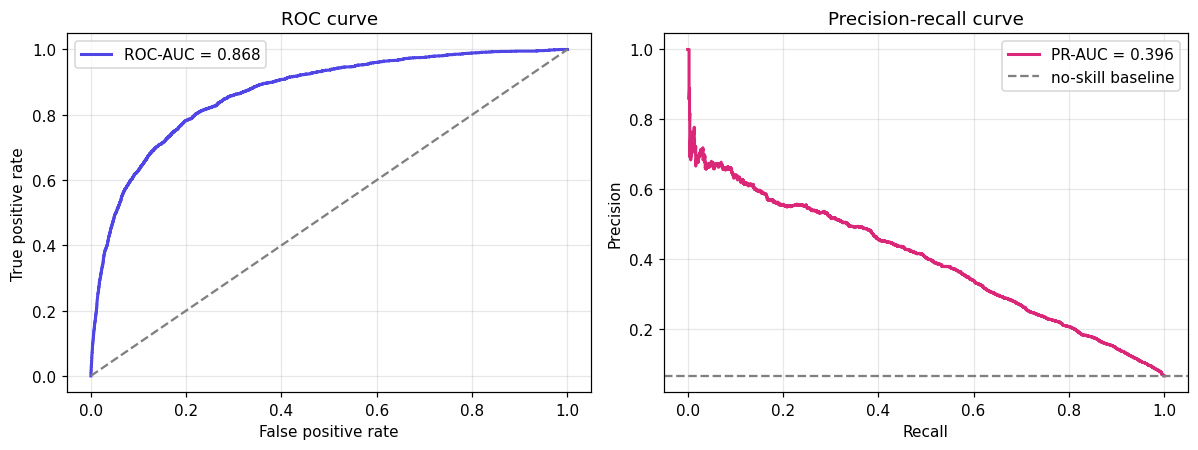

In [10]:
proba = best_pipe.predict_proba(X_test)[:, 1]
test_metrics = {
    "ROC-AUC": roc_auc_score(y_test, proba),
    "PR-AUC": average_precision_score(y_test, proba),
    "Brier": brier_score_loss(y_test, proba),
}
base_rate = float(y_test.mean())
print(f"Test rows: {len(y_test)} | delinquency rate: {base_rate:.4f}")
for k, v in test_metrics.items():
    print(f"{k:8s}: {v:.4f}")
print(f"PR-AUC of a model with no skill equals the base rate: {base_rate:.4f}")
print(f"Accuracy of 'approve everyone': {1 - base_rate:.4f} (this is why accuracy is not used)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
fpr, tpr, _ = roc_curve(y_test, proba)
ax[0].plot(fpr, tpr, color="#4F46E5", lw=2, label=f"ROC-AUC = {test_metrics['ROC-AUC']:.3f}")
ax[0].plot([0, 1], [0, 1], "--", color="grey")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].set_title("ROC curve"); ax[0].legend()
pr, rc, _ = precision_recall_curve(y_test, proba)
ax[1].plot(rc, pr, color="#DB2777", lw=2, label=f"PR-AUC = {test_metrics['PR-AUC']:.3f}")
ax[1].axhline(base_rate, color="grey", ls="--", label="no-skill baseline")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-recall curve"); ax[1].legend()
plt.tight_layout()
plt.savefig("fig_test_eval.png", dpi=150)
plt.show()

## 8. From probability to decision: calibration and a cost-based threshold
A calibration curve checks whether a predicted 10 percent risk really means about 10 percent of such borrowers become delinquent. For the decision rule, approving a borrower who later becomes seriously delinquent is assumed to cost 5 times more than declining a good one. This ratio is an assumption for illustration and can be changed below. The threshold is chosen on out-of-fold training predictions, then checked on the test set.

Decline threshold (cost-optimal, from cross-validation): 0.160
Average cost per applicant on the test set:
   approve everyone : 0.3342
   decline everyone : 0.9332
   this model       : 0.2107  (36.9% below the best no-model policy)

Decision at the threshold, on the test set:
   Decline rate: 0.110
   Default rate among approved: 0.031
   Default rate among declined: 0.354
   Share of all defaulters caught (recall): 0.582
   Precision of declines: 0.354
   F1 of declines: 0.440
   (overall default rate: 0.067)


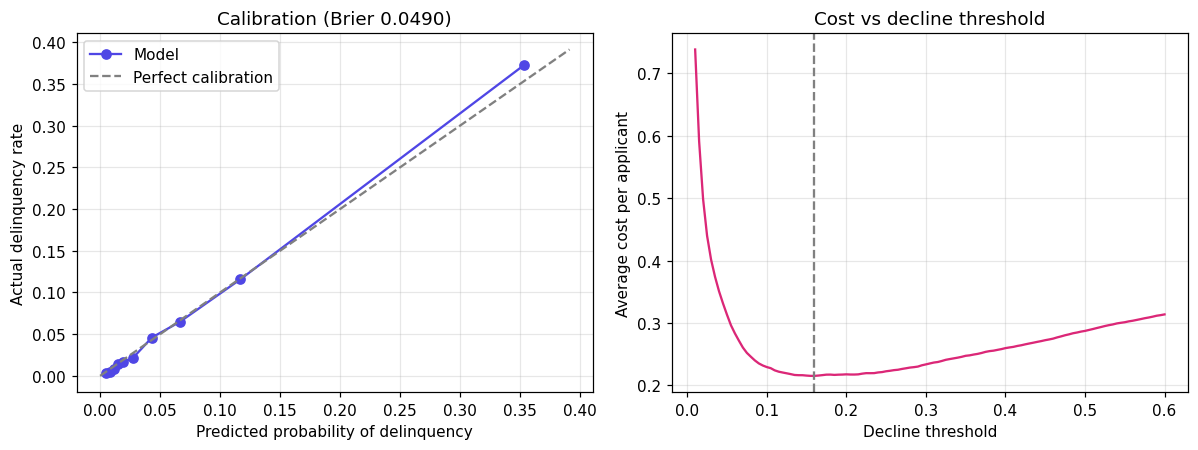

In [11]:
COST_BAD_APPROVED, COST_GOOD_DECLINED = 5, 1


def cost_at(t, yt, p):
    decline = p >= t
    return COST_BAD_APPROVED * np.sum(~decline & (yt == 1)) + COST_GOOD_DECLINED * np.sum(decline & (yt == 0))


oof = cross_val_predict(best_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
ths = np.linspace(0.01, 0.60, 119)
costs = np.array([cost_at(t, y_train.values, oof) for t in ths]) / len(y_train)
t_star = float(ths[int(np.argmin(costs))])
t_review = 0.5 * t_star
n = len(y_test)
cost_all = COST_BAD_APPROVED * y_test.mean()
cost_none = COST_GOOD_DECLINED * (1 - y_test.mean())
cost_model = cost_at(t_star, y_test.values, proba) / n
print(f"Decline threshold (cost-optimal, from cross-validation): {t_star:.3f}")
print(f"Average cost per applicant on the test set:")
print(f"   approve everyone : {cost_all:.4f}")
print(f"   decline everyone : {cost_none:.4f}")
print(f"   this model       : {cost_model:.4f}  ({(1 - cost_model / min(cost_all, cost_none)) * 100:.1f}% below the best no-model policy)")

decline = proba >= t_star
policy = {
    "Decline rate": float(decline.mean()),
    "Default rate among approved": float(y_test[~decline].mean()),
    "Default rate among declined": float(y_test[decline].mean()),
    "Share of all defaulters caught (recall)": float(recall_score(y_test, decline)),
    "Precision of declines": float(precision_score(y_test, decline)),
    "F1 of declines": float(f1_score(y_test, decline)),
}
print("\nDecision at the threshold, on the test set:")
for k, v in policy.items():
    print(f"   {k}: {v:.3f}")
print(f"   (overall default rate: {base_rate:.3f})")

frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].plot(mean_pred, frac_pos, "o-", color="#4F46E5", label="Model")
lim = max(mean_pred.max(), frac_pos.max()) * 1.05
ax[0].plot([0, lim], [0, lim], "--", color="grey", label="Perfect calibration")
ax[0].set_xlabel("Predicted probability of delinquency"); ax[0].set_ylabel("Actual delinquency rate")
ax[0].set_title(f"Calibration (Brier {test_metrics['Brier']:.4f})"); ax[0].legend()
ax[1].plot(ths, costs, color="#DB2777")
ax[1].axvline(t_star, color="grey", ls="--")
ax[1].set_xlabel("Decline threshold"); ax[1].set_ylabel("Average cost per applicant"); ax[1].set_title("Cost vs decline threshold")
plt.tight_layout()
plt.savefig("fig_calibration_cost.png", dpi=150)
plt.show()

## 9. Explainability: which inputs matter?
Each original input is shuffled in turn on a 10,000-row sample of the test set (features are rebuilt each time). The bigger the drop in ROC-AUC, the more the model relies on that input.

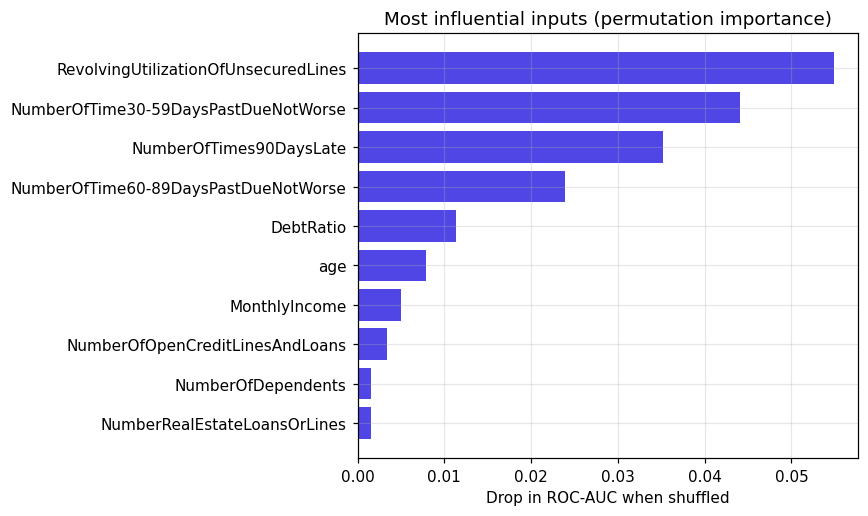

,0
RevolvingUtilizationOfUnsecuredLines,0.0549
NumberOfTime30-59DaysPastDueNotWorse,0.0441
NumberOfTimes90DaysLate,0.0352
NumberOfTime60-89DaysPastDueNotWorse,0.0239
DebtRatio,0.0114
age,0.0078
MonthlyIncome,0.0050
NumberOfOpenCreditLinesAndLoans,0.0034
NumberOfDependents,0.0016
NumberRealEstateLoansOrLines,0.0016


In [12]:
def raw_importance(pipe, Xraw, y, caps, n_repeats=5, n=10000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(Xraw), size=min(n, len(Xraw)), replace=False)
    Xs, ys = Xraw.iloc[idx].reset_index(drop=True), y.iloc[idx].reset_index(drop=True)
    base = roc_auc_score(ys, pipe.predict_proba(add_features(Xs, caps))[:, 1])
    out = {}
    for c in Xs.columns:
        drops = []
        for _ in range(n_repeats):
            Xp = Xs.copy()
            Xp[c] = rng.permutation(Xp[c].values)
            drops.append(base - roc_auc_score(ys, pipe.predict_proba(add_features(Xp, caps))[:, 1]))
        out[c] = float(np.mean(drops))
    return pd.Series(out).sort_values(ascending=False)


imp = raw_importance(best_pipe, X_test_raw, y_test, caps)
top = imp.head(10)[::-1]
plt.figure(figsize=(8, 4.8))
plt.barh(top.index, top.values, color="#4F46E5")
plt.xlabel("Drop in ROC-AUC when shuffled")
plt.title("Most influential inputs (permutation importance)")
plt.tight_layout()
plt.savefig("fig_importance.png", dpi=150)
plt.show()
imp.round(4)

## 10. Fairness check by age
This dataset has no sex or race columns, but age is present and is a legally sensitive attribute in lending. Decisions are compared across age groups on the test set, first with age in the model and then with age removed. Removing a column does not guarantee fairness, because other features can act as proxies (for example income and number of credit lines).

In [13]:
age_group = np.select([X_test_raw["age"] < 30, X_test_raw["age"] < 60], ["under 30", "30 to 59"], default="60 and over")
y_arr = y_test.values


def group_table(p):
    d = p >= t_star
    out = []
    for g in ["under 30", "30 to 59", "60 and over"]:
        m = age_group == g
        out.append({"Age group": g, "n": int(m.sum()), "Actual default rate": y_arr[m].mean(),
                    "Mean predicted risk": p[m].mean(), "Declined": d[m].mean(),
                    "Declined among non-defaulters": d[m & (y_arr == 0)].mean(),
                    "Caught among defaulters": d[m & (y_arr == 1)].mean()})
    return pd.DataFrame(out).set_index("Age group").round(3)


fair_with = group_table(proba)
noage_pipe = clone(best_pipe).fit(X_train.drop(columns="age"), y_train)
proba_noage = noage_pipe.predict_proba(X_test.drop(columns="age"))[:, 1]
fair_without = group_table(proba_noage)
auc_with, auc_without = roc_auc_score(y_test, proba), roc_auc_score(y_test, proba_noage)
print(f"Test ROC-AUC with age: {auc_with:.4f} | without age: {auc_without:.4f}\n")
print("WITH age in the model:")
display(fair_with)
print("WITHOUT age in the model:")
display(fair_without)

Test ROC-AUC with age: 0.8681 | without age: 0.8641

WITH age in the model:


,n,Actual default rate,Mean predicted risk,Declined,Declined among non-defaulters,Caught among defaulters
Age group,,,,,,
under 30,1803,0.126,0.113,0.196,0.131,0.643
30 to 59,18546,0.081,0.079,0.134,0.094,0.589
60 and over,9651,0.029,0.034,0.046,0.033,0.495


WITHOUT age in the model:


,n,Actual default rate,Mean predicted risk,Declined,Declined among non-defaulters,Caught among defaulters
Age group,,,,,,
under 30,1803,0.126,0.104,0.190,0.126,0.634
30 to 59,18546,0.081,0.077,0.131,0.092,0.579
60 and over,9651,0.029,0.040,0.051,0.038,0.509


## 11. Save the model for the web app

In [14]:
ui_steps = {"RevolvingUtilizationOfUnsecuredLines": 0.01, "DebtRatio": 0.05, "MonthlyIncome": 100.0}
ui_stats = {}
for c in X_train_raw.columns:
    hi = float(np.ceil(X_train_raw[c].quantile(0.995)))
    med = float(X_train_raw[c].median())
    ui_stats[c] = {"min": 18.0 if c == "age" else 0.0, "max": max(hi, med + 1.0), "median": med, "step": ui_steps.get(c, 1.0)}
meta = {
    "pipeline": best_pipe,
    "model_name": best_name,
    "caps": caps,
    "raw_cols": X_train_raw.columns.tolist(),
    "ui_stats": ui_stats,
    "t_star": t_star,
    "t_review": t_review,
    "base_rate": float(y_train.mean()),
    "cv_table": cv_df[list(scoring)].reset_index().to_dict("records"),
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
    "policy": policy,
    "importance": {k: float(v) for k, v in imp.head(10).round(4).items()},
    "fair_with": fair_with.reset_index().to_dict("records"),
    "fair_without": fair_without.reset_index().to_dict("records"),
    "auc_with_age": float(auc_with),
    "auc_without_age": float(auc_without),
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
}
joblib.dump(meta, "credit_model.joblib")
import sklearn, sys
print("Saved credit_model.joblib | size: %.1f MB" % (os.path.getsize("credit_model.joblib") / 1e6))
print("sklearn:", sklearn.__version__, "| python:", sys.version.split()[0])
try:
    from google.colab import files
    files.download("credit_model.joblib")
except ImportError:
    print("Not running in Colab, file saved in the current folder.")

Saved credit_model.joblib | size: 12.3 MB
sklearn: 1.6.1 | python: 3.13.16


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
lines = ["=== PROJECT 2 SUMMARY (copy everything from here to the end and send it) ==="]
lines.append(f"Dataset: Give Me Some Credit, {len(df)} rows after cleaning, delinquency rate {df[TARGET].mean():.4f}")
lines.append(f"Train/test: {len(X_train)}/{len(X_test)}")
lines.append("CV results (5-fold, train set):\n" + cv_df[list(scoring)].to_string())
lines.append(f"Selected: {best_name} | params: {grid.best_params_} | CV AUC 5-fold {base_auc:.4f}, tuned 3-fold {grid.best_score_:.4f}")
lines.append("Test metrics: " + str({k: round(float(v), 4) for k, v in test_metrics.items()}) + f" | base rate {base_rate:.4f}")
lines.append(f"Decline threshold {t_star:.3f} (review from {t_review:.3f}); cost per applicant: approve-all {cost_all:.4f}, decline-all {cost_none:.4f}, model {cost_model:.4f}")
lines.append("Policy on test: " + str({k: round(v, 3) for k, v in policy.items()}))
lines.append("Importance (drop in ROC-AUC):\n" + imp.head(10).round(4).to_string())
lines.append(f"Age fairness: test AUC with age {auc_with:.4f}, without {auc_without:.4f}")
lines.append("WITH age:\n" + fair_with.to_string())
lines.append("WITHOUT age:\n" + fair_without.to_string())
print("\n".join(lines))

with zipfile.ZipFile("project2_figures.zip", "w") as z:
    for f in glob.glob("fig_*.png"):
        z.write(f)
try:
    from google.colab import files
    files.download("project2_figures.zip")
except ImportError:
    pass

=== PROJECT 2 SUMMARY (copy everything from here to the end and send it) ===
Dataset: Give Me Some Credit, 149999 rows after cleaning, delinquency rate 0.0668
Train/test: 119999/30000
CV results (5-fold, train set):
                                  ROC-AUC             PR-AUC              Brier
Model                                                                          
Logistic Regression     0.8560 +/- 0.0069  0.3848 +/- 0.0092  0.0500 +/- 0.0004
Random Forest           0.8631 +/- 0.0061  0.3992 +/- 0.0083  0.0492 +/- 0.0004
Hist Gradient Boosting  0.8622 +/- 0.0056  0.3974 +/- 0.0079  0.0492 +/- 0.0004
Selected: Random Forest | params: {'model__max_depth': 12, 'model__min_samples_leaf': 20, 'select__k': 'all'} | CV AUC 5-fold 0.8631, tuned 3-fold 0.8639
Test metrics: {'ROC-AUC': 0.8681, 'PR-AUC': 0.3956, 'Brier': 0.049} | base rate 0.0668
Decline threshold 0.160 (review from 0.080); cost per applicant: approve-all 0.3342, decline-all 0.9332, model 0.2107
Policy on test: {'Decline

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>